## Simulación Monte Carlo y Black-Scholes

José Armando Melchor Soto
| 24/08/2026

---

### Libraries 

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

### Fórmula 


$$S(t) = S(0) e^{(r-\frac{1}{2}\sigma^2)t + \sigma W(t)}$$

$$W(t) = \sqrt{T} z$$

]

### Datos

In [53]:
S0 = 100
k = 110
r = 0.05
sigma = 0.20
T = 1
M = 10e3

#### Precio final 

$$S(t) = S(0) e^{(r-\frac{1}{2}\sigma^2)t + \sigma\sqrt{T} z}$$


#### Variable aleatoria normal estándar
$$z ∈  N(0,1) $$

In [54]:
np.random.seed(42)

z = np.random.normal(0,1 , size = int(M))
St= S0 * np.exp((r-1/2*sigma**2)*T + sigma*np.sqrt(T)*z)
St

array([113.8080226 , 100.23498965, 117.29684912, ...,  89.4882061 ,
       113.78643345, 117.21945676], shape=(10000,))

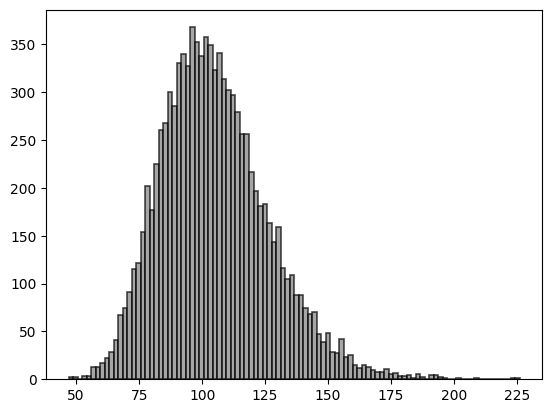

In [55]:
plt.hist(St, bins= 100,  density=False, color='grey', alpha=0.7, edgecolor='black' , linewidth=1.2)
plt.show()

---


$$\ln(S_T) \sim \phi \left[\ln S_0 + \left(\mu - \frac{\sigma^2}{2}\right)T, \sigma^2T\right]$$



$$(S(T) - k)^t = max({S(T)-k, 0})$$

In [56]:
S0 = 100
k = 110
r = 0.05
sigma = 0.20
T = 1
M = 10e3

##### Elimina en el histograma la ganancia o el valor en el que el precio de los universos sea menor que 110 


In [57]:
np.mean((St)*np.exp(-r*T))

np.float64(99.97139519524798)

Precio de la opción: 6.0447


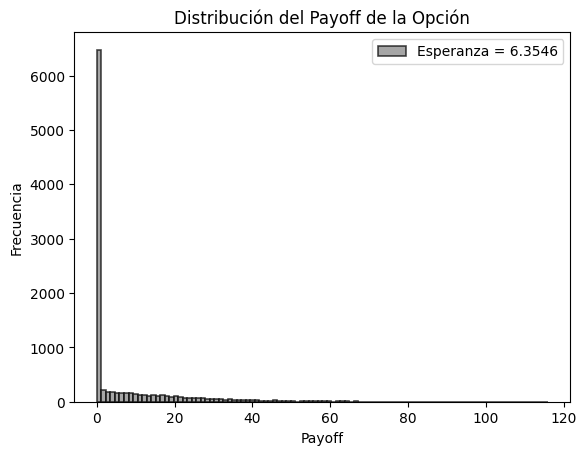

In [58]:
# Payoff tipo call: max(S(T) - K, 0), con K = 110
K = 110.0

payoff = np.where(St < K, 0, St - K)

precio_opcion = np.mean(np.exp(-r * T) * payoff)
print(f"Precio de la opción: {precio_opcion:.4f}")

plt.hist(payoff, bins= 100,  density=False, color='grey', alpha=0.7, edgecolor='black' , linewidth=1.2,  label=f'Esperanza = {payoff.mean():.4f}')
plt.xlabel('Payoff')
plt.ylabel('Frecuencia')
plt.title('Distribución del Payoff de la Opción')
plt.legend()
plt.show()

In [59]:
precio_opcion = np.mean(np.exp(-r * T) * payoff)
print(f"Precio de la opción: {precio_opcion:.4f}")

Precio de la opción: 6.0447


---

### Black Scholes 

  $$c = S_0 \cdot N(d_1) - K \cdot e^{-rT} \cdot N(d_2)$$

  donde:

  $$d_1 = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}$$

  $$d_2 = d_1 - \sigma\sqrt{T}$$

In [60]:
def black_scholes_call(S0, K, r, sigma, T):
    
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    N_d1 = norm.cdf(d1)
    N_d2 = norm.cdf(d2)

    c = S0 * N_d1 - K * np.exp(-r * T) * N_d2

    return c, d1, d2, N_d1, N_d2

# Valor de la opción de compra usando Black-Scholes
precio_bs, d1, d2, N_d1, N_d2 = black_scholes_call(S0, K, r, sigma, T)
print(f"Precio de la opción (Black-Scholes): {precio_bs:.4f}")
print(f'Precio de la opción (Simulación Monte Carlo): {precio_opcion:.4f}')

Precio de la opción (Black-Scholes): 6.0401
Precio de la opción (Simulación Monte Carlo): 6.0447
